# Spike School

The same n-gram counting trick can turn **terrain into a decision**. In this mini Geometry Dash, the output is an action **at the current tile**. [Play or watch ↓](#Play-or-watch)

`.` is a clear tile. `^` is a spike. **Walk** (`x`) moves one tile; **jump** (`j`) skips two tiles and lands on the third. Only the landing tile can hit you.

## Same near view, opposite moves

Start at the leftmost tile. Both tracks begin with `..^`. In A, walking first leaves you with a jump that lands on the second spike. In B, jumping immediately lands on the second spike.

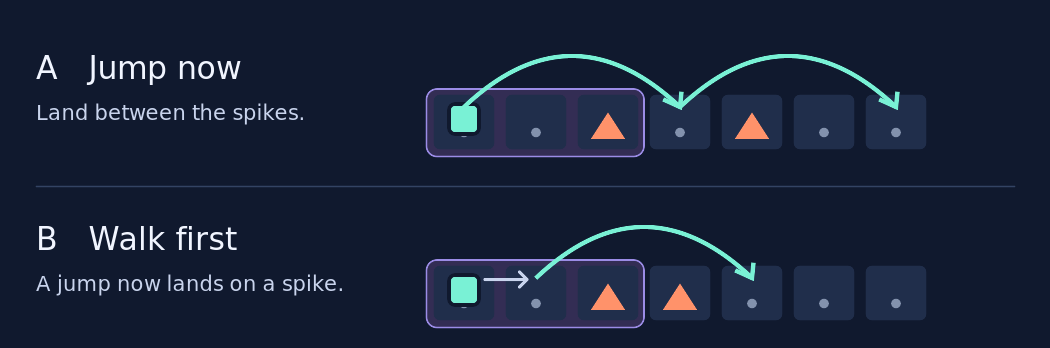

## One training row

Slide the window along the track, but record an action only where the teacher is **on the ground**. A 6-gram row contains the current tile, four visible tiles ahead, and one action. The action label belongs to the **first** tile; the tiles ahead are already visible when you decide.

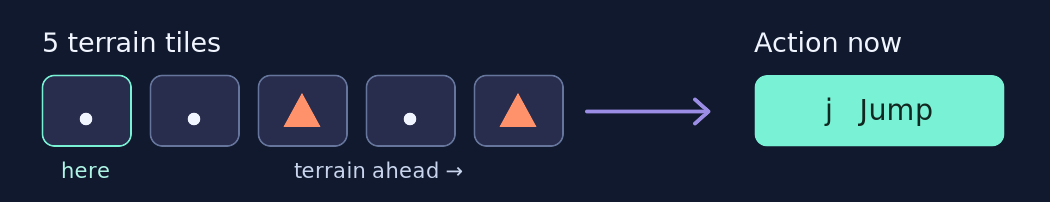

## Label the tracks

The teacher sees the whole track. Working backward from the finish, it marks a tile solvable if a walk or jump lands on a tile already marked solvable. When both work, it walks. We then follow the teacher to collect demonstrations.

In [1]:
from collections import Counter, defaultdict
from itertools import product

MOVES = {"x": 1, "j": 3}


def teacher(track):
    finish = len(track) - 1
    plan = {finish: None}
    for pos in range(finish - 1, -1, -1):
        if track[pos] == ".":
            for action, distance in MOVES.items():
                if pos + distance in plan:
                    plan[pos] = action
                    break
    return plan


def play(track, choose):
    pos, steps = 0, []
    finish = len(track) - 1
    while pos < finish and track[pos] == ".":
        action = choose(pos)
        if action is None:
            break
        steps.append((pos, action))
        pos += MOVES[action]
    return pos == finish, steps

## Count the actions

Group the demonstrations by their tile window and count `x` and `j`. At play time, the model picks the more frequent action in its own window. If it has never seen a window, it stops. Near the finish, pad the window with clear tiles; landing past the finish still loses.

In [2]:
def levels(length):
    return ["." + "".join(tiles) + "."
            for tiles in product(".^", repeat=length - 2) if "^" in tiles]


def window(track, pos, width):
    return track[pos : pos + width].ljust(width, ".")


widths = {"short": 3, "wide": 5}  # Current tile + 2 or 4 ahead.
models = {name: defaultdict(Counter) for name in widths}
for track in levels(9):
    cleared, steps = play(track, teacher(track).get)
    if cleared:
        for pos, action in steps:
            for name, width in widths.items():
                models[name][window(track, pos, width)][action] += 1


def predict(name, track, pos):
    counts = models[name].get(window(track, pos, widths[name]))
    return counts.most_common(1)[0][0] if counts else None

## Judge the whole run

Train on nine-tile tracks and test on **solvable eleven-tile tracks**. The score is tracks cleared, not actions matched: two different moves can both be good. A longer window helps, but it can still miss a trap beyond its view.

In [3]:
test = [track for track in levels(11) if 0 in teacher(track)]
for name, label in [("short", "Short view"), ("wide", "Five-tile view")]:
    wins = sum(play(track, lambda pos: predict(name, track, pos))[0] for track in test)
    print(f"{label}: {wins}/{len(test)} tracks cleared ({wins / len(test):.0%})")

Short view: 108/179 tracks cleared (60%)
Five-tile view: 142/179 tracks cleared (79%)


## Play or watch

In **Watch policy**, the outline shows the model’s current window and the counts show what it learned. Try both policies on **Double jump**, or switch to **Your track** for the late `^.^` trap.

In [4]:
from html import escape
from json import dumps
from pathlib import Path
from IPython.display import display

tracks = {"Double jump": "..^.^..", "Twin spikes": "..^^...",
          "Your track": "..^^...^....^.^..."}

demo = {"tracks": tracks, "moves": MOVES, "models": {}}
for name, counts_by_window in models.items():
    table = {key: {"action": counts.most_common(1)[0][0], "x": counts["x"], "j": counts["j"]}
             for key, counts in counts_by_window.items()}
    demo["models"][name] = {"width": widths[name], "table": table}

page = Path("spike_arcade.html").read_text(encoding="utf-8")
page = page.replace("__DEMO_JSON__", dumps(demo).replace("<", "\\u003c"))
arcade = (f'<iframe title="Spike Arcade" sandbox="allow-scripts" '
          f'style="display:block;width:100%;max-width:900px;height:460px;border:0" srcdoc="{escape(page, quote=True)}"></iframe>')
display({"text/html": arcade}, raw=True)

<iframe title="Spike Arcade" sandbox="allow-scripts" style="display:block;width:100%;max-width:900px;height:460px;border:0" srcdoc="<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<style>
:root{font:16px system-ui,sans-serif;color:#f1f5ff;color-scheme:dark}
*{box-sizing:border-box}body{margin:0}
main{padding:17px;background:#10192e;border:1px solid #334363;border-radius:15px}
header,.bar,.moves,.modes{display:flex;align-items:center;gap:7px;flex-wrap:wrap}
.moves[hidden]{display:none}
header,.bar{justify-content:space-between}.bar{margin-top:10px}
h1{font-size:19px;margin:0;letter-spacing:-.025em}.modes{margin-top:12px}
button,select{font:600 14px system-ui;min-height:43px;padding:7px 12px;border-radius:8px;border:1px solid #536283;background:#202d48;color:#f1f5ff;cursor:pointer;touch-action:manipulation}
button[aria-pressed="true"],button.primary{background:#79f1d5;color:#112820;border-color:#79f1d5}
main[data-driver="policy"] button[aria-pressed="true"],main[data-driver="policy"] button.primary{background:#c9baff;color:#231943;border-color:#c9baff}
button:disabled{opacity:.45;cursor:default}button:focus-visible,select:focus-visible{outline:2px solid #fcd585;outline-offset:2px}
#track{max-width:100%}#board{width:100%;display:block;margin-top:12px;background:#151f35;border:1px solid #354669;border-radius:9px}
#readout{margin:10px 0 0;display:flex;gap:7px 14px;align-items:center;flex-wrap:wrap;min-height:34px}
#readout[hidden]{display:none}.tokens{display:inline-flex;gap:4px}
.tokens b{display:block;width:24px;text-align:center;border-radius:5px;background:#353159;color:#f0e8ff;font:700 19px ui-monospace,monospace}
.tokens b:first-child{outline:1px solid #aef5e5;color:#aef5e5}
#decision{font-size:14px;font-weight:600}#status{font-size:14px;font-weight:650;margin:0;min-height:21px}
@media(max-width:470px){main{padding:12px}h1{font-size:17px}button,select{padding:6px 9px;font-size:13px}}
</style>
</head>
<body>
<main>
 <header><h1>Spike Arcade</h1><select id="track" aria-label="Track"></select></header>
 <div class="modes" role="group" aria-label="Driver">
 <button data-mode="you" aria-pressed="true">Play yourself</button>
 <button data-mode="policy" aria-pressed="false">Watch policy</button>
 </div>
 <svg id="board" viewBox="0 0 680 166" role="img" aria-label="Spike track"></svg>
 <div id="readout" hidden><span id="window" class="tokens"></span><span id="decision"></span></div>
 <div class="bar">
 <div class="moves">
 <div id="manual-controls" class="moves">
 <button id="walk">Walk</button><button id="jump" class="primary">Jump</button>
 </div>
 <div id="policy-controls" class="moves" hidden>
 <select id="policy" aria-label="Policy">
 <option value="wide">Five-tile view</option>
 <option value="short">Short view</option>
 </select>
 <button id="play" class="primary">Pause</button><button id="step">Step once</button>
 </div>
 <button id="reset">Reset</button>
 </div>
 <p id="status" role="status"></p>
 </div>
</main>
<script>
const demo = {"tracks": {"Double jump": "..^.^..", "Twin spikes": "..^^...", "Your track": "..^^...^....^.^..."}, "moves": {"x": 1, "j": 3}, "models": {"short": {"width": 3, "table": {"...": {"action": "x", "x": 101, "j": 0}, "..^": {"action": "x", "x": 38, "j": 15}, ".^.": {"action": "j", "x": 0, "j": 36}, ".^^": {"action": "j", "x": 0, "j": 36}}}, "wide": {"width": 5, "table": {".....": {"action": "x", "x": 61, "j": 0}, "....^": {"action": "x", "x": 12, "j": 0}, "...^.": {"action": "x", "x": 19, "j": 0}, "..^..": {"action": "x", "x": 19, "j": 9}, ".^...": {"action": "j", "x": 0, "j": 30}, "...^^": {"action": "x", "x": 9, "j": 0}, "..^^.": {"action": "x", "x": 19, "j": 0}, ".^^..": {"action": "j", "x": 0, "j": 30}, "..^.^": {"action": "j", "x": 0, "j": 6}, ".^..^": {"action": "j", "x": 0, "j": 6}, ".^^.^": {"action": "j", "x": 0, "j": 6}}}}};
const $ = id => document.getElementById(id);
const board = $('board');
const select